In [703]:
'''
this notebook demonstrates the following:
1. when hebbian patterns are heavily tailed (element wise) then instead of converging to a pattern, network typically converges to a pattern mixture.
2. gentle strengthening or weakening patterns by e.g. 10% will shift the point of attraction to slightly different mixture rather than make it stick to one of the patterns.
'''

'\nthis notebook demonstrates the following:\n1. when hebbian patterns are heavily tailed (element wise) then instead of converging to a pattern, network typically converges to a pattern mixture.\n2. gentle strengthening or weakening patterns by e.g. 10% will shift the point of attraction to slightly different mixture rather than make it stick to one of the patterns.\n'

In [704]:
import numpy as np
import matplotlib.pyplot as plt


In [705]:
def generate_patterns(distribution, num_patterns, pattern_size):
    if distribution == 'gaussian':
        return np.random.randn(num_patterns, pattern_size)
    if distribution == 'laplace':
        return np.random.laplace(loc=0.0, scale=1.0, size=(num_patterns, pattern_size))
    if distribution == 'uniform':
        return np.random.uniform(low=-2.0, high=2.0, size=(num_patterns, pattern_size))
    raise ValueError(f"Unsupported distribution type: {distribution}")

In [706]:
def run_dynamics(x0, W, phi, g=2, num_steps=100):
    x = x0
    xt = np.zeros((num_steps + 1, *x.shape))
    preacts = np.zeros((num_steps + 1, *x.shape))
    xt[0, :, :] = x
    preacts[0, :, :] = g * (x @ W)

    for t in range(1, num_steps + 1):
        h = g * (x @ W)
        preacts[t, :, :] = h
        x = phi(h)
        xt[t, :, :] = x

    return x, xt, preacts


def create_hebbian_weights(xi, pattern_weights=None, output_transform=None, normalize=True):
    num_patterns = xi.shape[0]

    if pattern_weights is None:
        pattern_weights = np.eye(num_patterns)
    else:
        pattern_weights = np.asarray(pattern_weights, dtype=float)
        if pattern_weights.shape != (num_patterns, num_patterns):
            raise ValueError(
                f"`pattern_weights` must have shape {(num_patterns, num_patterns)}, got {pattern_weights.shape}."
            )

    if output_transform is None:
        output_transform = np.eye(num_patterns)
    else:
        output_transform = np.asarray(output_transform, dtype=float)
        if output_transform.shape != (num_patterns, num_patterns):
            raise ValueError(
                f"`output_transform` must have shape {(num_patterns, num_patterns)}, got {output_transform.shape}."
            )

    output_patterns = output_transform @ xi
    W = output_patterns.T @ pattern_weights @ xi

    if normalize:
        W /= xi.shape[1]

    return W


In [707]:
#phi = np.tanh
#let phi be a logistic sigmoid:
phi = lambda x: 1/(1+np.exp(-x))
relu = lambda x: np.maximum(0, x)
# sample_from = 'random_from_positive_orthant'
# sample_from = 'random_everywhere'
sample_from = 'equally_spaced_from_circle'
n = 20_000
p = 2
xi = generate_patterns('laplace', p, n)
# xi = generate_patterns('gaussian', p, n)
# xi = generate_patterns('laplace', p, n)


In [708]:
''' 
gnenerate random initial states in the positive orthant and see where they converge to.
'''
n_k = 40 #number of initial states to test
if sample_from == 'positive_orthant':
    bnd_off_zero = 0.1
    k = np.random.rand(n_k,p)*(1-bnd_off_zero) + bnd_off_zero #random initial mixture weights
elif sample_from == 'random_everywhere':
    k = np.random.rand(n_k,p) - 0.5
elif sample_from == 'equally_spaced_from_circle':
    angles = np.linspace(0, 2*np.pi, n_k, endpoint=False)
    k = np.column_stack((np.cos(angles), np.sin(angles)))
'L2 normalize the rows of k to have unit norm'
k = k / np.linalg.norm(k, axis=1, keepdims=True)

x0 = k @ xi #random initial states as random mixtures of the patterns


perturb_amp = 0.0
dim_to_perturb = [None] #+ list(range(p)) #the first entry corresponds to no perturbation, then we will perturb each pattern in turn

all_projs = []

for dd, this_dim_to_perturb in enumerate(dim_to_perturb):
    pattern_weights_deltas = np.zeros(p)
    if this_dim_to_perturb is not None:
        pattern_weights_deltas[this_dim_to_perturb] = perturb_amp
    W = create_hebbian_weights(xi) #, pattern_weights_deltas=pattern_weights_deltas)
    #laplace-distributed vector in the direction of the first column of xi, to perturb the first pattern in the weight matrix
    # xi_perturb = np.random.laplace(loc=0.0, scale=1.0, size=(1, p))

    # xi_perturb = np.random.laplace(loc=0.0, scale=1.0, size=(n,1)) - 0.3

    # pp = perturb_amp*xi_perturb[0,:].reshape(-1,1) @ xi_perturb[0,:].reshape(1,-1)

    xi_perturb = n**(-0.5) * (xi[0,:] - 0.4)
    pp = perturb_amp*xi_perturb.reshape(-1,1) @ xi_perturb.reshape(1,-1) 
    # pp = relu(pp) #make sure the perturbation is positive semi-definite
    # pp = 0

    W = W + pp  #perturb the first pattern by adding a rank-1 matrix to the weight matrix
    final_states, trajectories, preacts = run_dynamics(x0, W, phi, g=4.6, num_steps=100)
    all_projs.append(trajectories @ xi.T)




In [709]:
xi_perturb

array([ 0.0052531 , -0.01601615,  0.00416772, ..., -0.00697068,
        0.00960457,  0.00462448])

In [710]:
phi(-10)

4.5397868702434395e-05

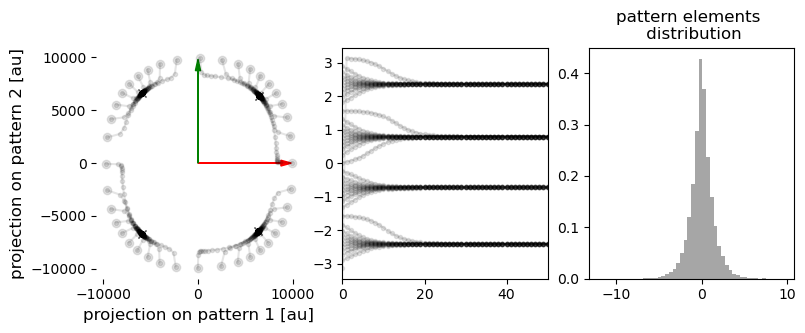

In [711]:
colors = ['k', 'r', 'g', 'b']
plt.figure(figsize=(9, 3))
lim = 1.1*np.max(np.abs((all_projs))[:,1:])
for dd, this_dim_to_perturb in enumerate(dim_to_perturb[:4]):
    projs = all_projs[dd][1:]
    for i in range(n_k):
        plt.subplot(1, 3, 1)
        plt.plot(projs[:, i, 0], projs[:, i, 1],'.-', alpha=0.1, color=colors[dd])
        plt.plot(projs[-1, i, 0], projs[-1, i, 1],'x', alpha=0.1, color=colors[dd])
        plt.plot(projs[0, i, 0], projs[0, i, 1],'o', alpha=0.1, color=colors[dd])
        # plt.xlim(0, lim)
        # plt.ylim(0, lim)
        plt.xlabel('projection on pattern 1 [au]', fontsize=12)
        plt.ylabel('projection on pattern 2 [au]', fontsize=12)

        plt.subplot(1, 3, 2)
        plt.plot(np.arctan2(projs[:, i, 0], projs[:, i, 1]),'.-', alpha=0.1, color=colors[dd])
        plt.xlim( [0, 50])




plt.subplot(1, 3, 1)
plt.arrow(0, 0, lim*0.8, 0, head_width=lim*0.05, head_length=lim*0.1, fc=colors[1], ec=colors[1])
plt.arrow(0, 0, 0, lim*0.8, head_width=lim*0.05, head_length=lim*0.1, fc=colors[2], ec=colors[2])
plt.box(False)
plt.subplot(1, 3, 3)
plt.hist(xi.flatten(), bins=50, color='gray', alpha=0.7,density=True)
plt.title('pattern elements \n distribution')
# plt.subplot(1, 3, 2)
# plt.arrow(0, 0, lim*0.8, 0, head_width=lim*0.05, head_length=lim*0.1, fc=colors[2], ec=colors[2])
# plt.arrow(0, 0, 0, lim*0.8, head_width=lim*0.05, head_length=lim*0.1, fc=colors[3], ec=colors[3])
# plt.box(False)
# ax = plt.subplot(1, 3, 3, projection='3d')
# for dd,this_dim_to_perturb in enumerate(dim_to_perturb[:4]):
#     ax.quiver(0, 0, 0, lim*0.8 if this_dim_to_perturb==0 else 0, lim*0.8 if this_dim_to_perturb==1 else 0, lim*0.8 if this_dim_to_perturb==2 else 0,
#                 arrow_length_ratio=0.1, color=colors[dd])
plt.show()



In [712]:
i,dd,2

(39, 0, 2)

In [713]:
# import pickle
# with open('./experimental/optim/hebbian_subproj/hebbian_attract_demo101_p7_d0p15_g1p05.pkl', 'wb') as f:
#     pickle.dump(all_projs, f)

In [714]:
dim_to_perturb

[None]